## Run SUMMA deterministic evaluation ##

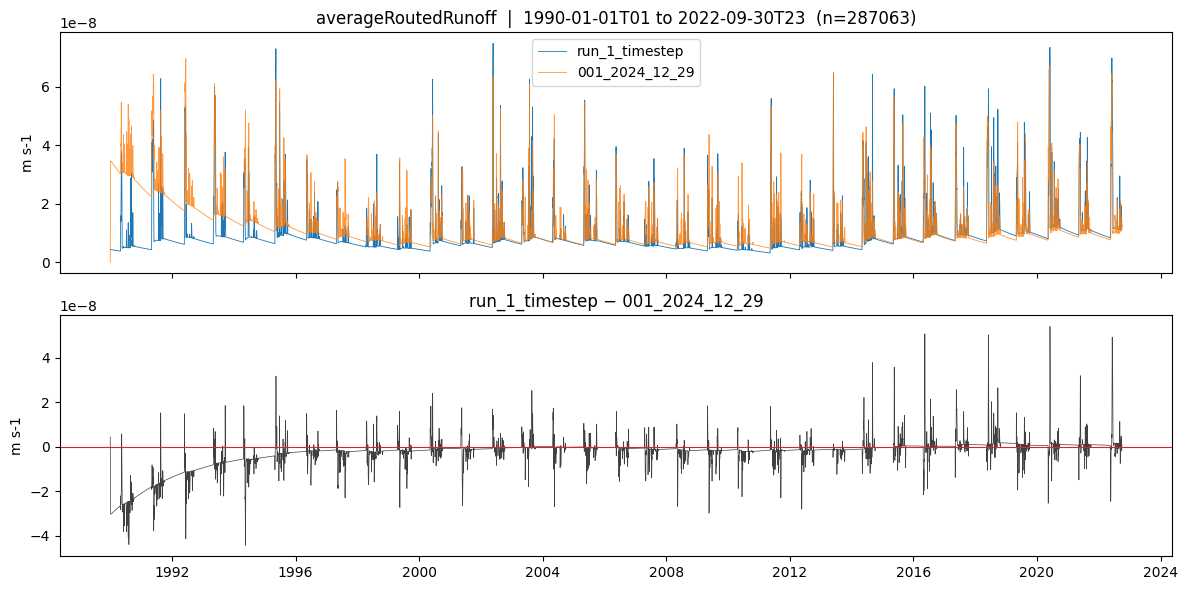

averageRoutedRunoff: n=287063, bias=-2.714e-09, rmse=7.271e-09, max|diff|=5.404e-08 m s-1


(<xarray.DataArray 'averageRoutedRunoff' (time: 287063)> Size: 2MB
 array([4.37460177e-09, 4.37439441e-09, 4.37418706e-09, ...,
        1.26500320e-08, 1.26522315e-08, 1.26531422e-08], shape=(287063,))
 Coordinates:
   * time     (time) datetime64[ns] 2MB 1990-01-01T01:00:00 ... 2022-09-30T23:...
 Attributes:
     long_name:  routed runoff (instant)
     units:      m s-1,
 <xarray.DataArray 'averageRoutedRunoff' (time: 287063)> Size: 2MB
 array([8.02678294e-13, 6.77945456e-12, 2.31632844e-11, ...,
        1.17462705e-08, 1.16784260e-08, 1.16122250e-08], shape=(287063,))
 Coordinates:
   * time     (time) datetime64[ns] 2MB 1990-01-01T01:00:00 ... 2022-09-30T23:...
 Attributes:
     long_name:  routed runoff (instant)
     units:      m s-1)

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr



def _hourly_series(ds: xr.Dataset, variable: str) -> xr.DataArray:
    """Squeeze a length-1 HRU/GRU series and snap time to the nearest hour."""
    da = ds[variable].squeeze(drop=True)
    extra = [dim for dim in da.dims if dim != "time"]
    if extra:
        raise ValueError(f"{variable} still has dims {extra}; expected one time series.")
    da = da.assign_coords(time=da.time.dt.round("h"))
    _, index = np.unique(da.time.values, return_index=True)
    return da.isel(time=np.sort(index))


def compare_summa_timesteps(
    path_a: str | Path = PATH_A,
    path_b: str | Path = PATH_B,
    variable: str | None = None,
    start: str | np.datetime64 | None = None,
    end: str | np.datetime64 | None = None,

    label_a: str = "run_1_timestep",
    label_b: str = "001_2024_12_29",
    resample: str | None = None,
):
    """Plot one shared variable on the overlapping timestamps of two SUMMA files.

    Hourly steps in these files carry sub-second noise, so times are rounded to
    the nearest hour before the inner join. ``start`` and ``end`` keep only that
    window of the overlap (either bound may be omitted). Leave ``variable`` unset
    for a dropdown when ipywidgets is available; otherwise the shared names are
    printed. ``resample`` (for example ``"1D"``) averages the window before plotting.
    """
    with xr.open_dataset(path_a) as ds_a, xr.open_dataset(path_b) as ds_b:
        shared = sorted(
            name
            for name in set(ds_a.data_vars) & set(ds_b.data_vars)
            if "time" in ds_a[name].dims and "time" in ds_b[name].dims
        )
        if not shared:
            raise ValueError("The two files have no shared time-varying variables.")

        def _plot(variable: str):
            if variable not in shared:
                raise KeyError(f"{variable!r} is not in both files. Choose from: {shared}")
            left, right = xr.align(
                _hourly_series(ds_a, variable),
                _hourly_series(ds_b, variable),
                join="inner",
            )
            if start is not None or end is not None:
                left = left.sel(time=slice(start, end))
                right = right.sel(time=slice(start, end))
            if left.sizes.get("time", 0) == 0:
                raise ValueError(
                    f"No overlapping times for {variable} between {start} and {end}."
                )
            if resample:
                left = left.resample(time=resample).mean()
                right = right.resample(time=resample).mean()
            left, right = left.load(), right.load()
            diff = left - right
            units = left.attrs.get("units") or right.attrs.get("units") or ""
            window_start = np.datetime_as_string(left.time.values[0], unit="h")
            window_end = np.datetime_as_string(left.time.values[-1], unit="h")

            fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
            axes[0].plot(left.time.values, left.values, lw=0.6, label=label_a)
            axes[0].plot(right.time.values, right.values, lw=0.6, alpha=0.8, label=label_b)
            axes[0].set_title(
                f"{variable}  |  {window_start} to {window_end}  (n={left.sizes['time']})"
            )
            axes[0].set_ylabel(units)
            axes[0].legend()
            axes[1].plot(diff.time.values, diff.values, color="0.25", lw=0.5)
            axes[1].axhline(0.0, color="C3", lw=0.8)
            axes[1].set_title(f"{label_a} − {label_b}")
            axes[1].set_ylabel(units)
            fig.tight_layout()
            plt.show()

            values = diff.values[np.isfinite(diff.values)]
            if values.size:
                print(
                    f"{variable}: n={values.size}, bias={values.mean():.4g}, "
                    f"rmse={np.sqrt(np.mean(values**2)):.4g}, "
                    f"max|diff|={np.max(np.abs(values)):.4g} {units}"
                )
            return left, right

        if variable is None:
            try:
                import ipywidgets as widgets
                from IPython.display import display
            except ImportError:
                print("Shared variables:", ", ".join(shared))
                print("Pass variable='...' to plot one.")
                return shared
            dropdown = widgets.Dropdown(options=shared, description="variable")
            display(widgets.VBox([dropdown, widgets.interactive_output(_plot, {"variable": dropdown})]))
            return None

        return _plot(variable)


PATH_A = Path("/Users/dcasson/GitHub/snowda/outputs/chena_summa_deterministic/20261104T153000Z/summa/001_2024_12_29_timestep.nc")
PATH_B = Path("/Users/dcasson/GitHub/snowda/models/run_1_timestep_chena.nc"
)
# airtemp, averageRoutedRunoff, pptrate
compare_summa_timesteps(
    path_a=PATH_A,
    path_b=PATH_B,
    variable="averageRoutedRunoff",
    start="1980-10-01",
    end="2022-09-30",
)


In [ ]:
from snowda.workflows.evaluate_streamflow import run_evaluation

sim_nc = ""
obs_csv = ""
run_evaluation(sim_nc, obs_csv, output_dir=..., resample="1D")

Wrote 46 water-year plots to /Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20261105T155633Z/evaluation/water_years


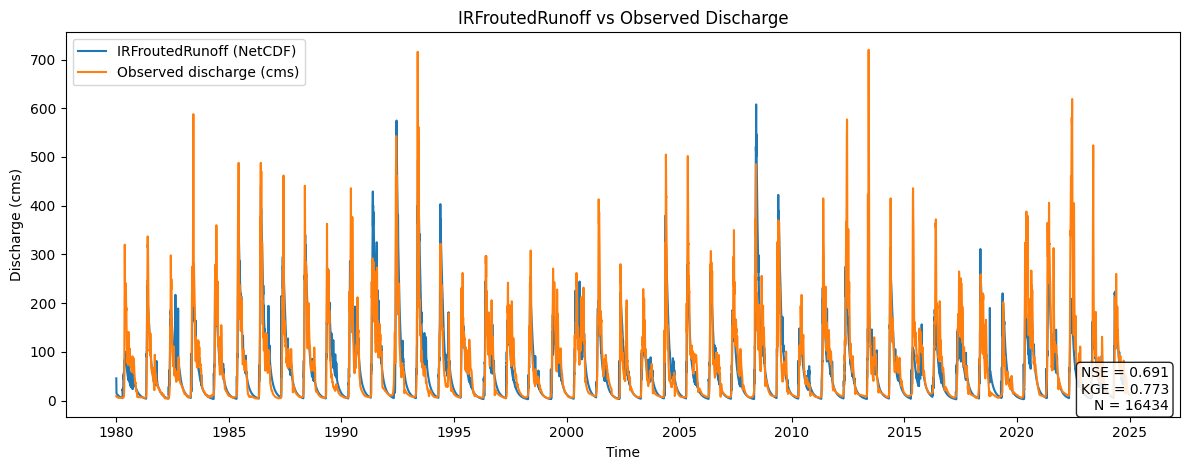

In [18]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional, Tuple, Union

from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from snowda.obs_qm.seasonal import water_year


def nse(sim: np.ndarray, obs: np.ndarray) -> float:
    """Nash–Sutcliffe Efficiency."""
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)

    m = np.isfinite(sim) & np.isfinite(obs)
    sim, obs = sim[m], obs[m]
    if sim.size < 2:
        return np.nan

    denom = np.sum((obs - np.mean(obs)) ** 2)
    if denom == 0:
        return np.nan
    return 1.0 - np.sum((obs - sim) ** 2) / denom


def kge(sim: np.ndarray, obs: np.ndarray) -> float:
    """Kling–Gupta Efficiency (Gupta et al., 2009)."""
    sim = np.asarray(sim, dtype=float)
    obs = np.asarray(obs, dtype=float)

    m = np.isfinite(sim) & np.isfinite(obs)
    sim, obs = sim[m], obs[m]
    if sim.size < 2:
        return np.nan

    # Pearson r
    if np.std(sim) == 0 or np.std(obs) == 0:
        r = np.nan
    else:
        r = np.corrcoef(sim, obs)[0, 1]

    mu_s, mu_o = np.mean(sim), np.mean(obs)
    sd_s, sd_o = np.std(sim, ddof=1), np.std(obs, ddof=1)

    alpha = sd_s / sd_o if sd_o != 0 else np.nan
    beta = mu_s / mu_o if mu_o != 0 else np.nan

    if not (np.isfinite(r) and np.isfinite(alpha) and np.isfinite(beta)):
        return np.nan

    return 1.0 - np.sqrt((r - 1.0) ** 2 + (alpha - 1.0) ** 2 + (beta - 1.0) ** 2)


def plot_irfroutedrunoff_vs_discharge(
    nc_path: Optional[str] = None,
    csv_path: Optional[str] = None,
    *,
    irf_var: str = "IRFroutedRunoff",
    seg_index: int = 0,
    csv_datetime_col: Optional[str] = None,
    csv_discharge_col: Optional[str] = None,
    resample_rule: str = "D",
    agg: str = "mean",
    timezone: Optional[str] = None,
    out_png: Optional[str] = None,
    title: Optional[str] = None,
    start: Optional[Union[str, pd.Timestamp]] = None,
    stop: Optional[Union[str, pd.Timestamp]] = None,
    water_year_dir: Optional[str] = None,
) -> Tuple[plt.Figure, plt.Axes, Optional[float], Optional[float]]:
    """
    Read IRFroutedRunoff from NetCDF and/or discharge (cms) from CSV, align in time if both provided,
    compute NSE + KGE if both present, and plot available series.

    Optional start/stop arguments bound the plotting, metric and series period.
    If water_year_dir is set, also write one PNG per water year (1 October through
    30 September) that has data inside that window. 1 Oct 2015 is water year 2016.

    Returns: (fig, ax, NSE, KGE) -- NSE/KGE are None if only one input provided.
    """
    sim = None
    obs = None

    # --- Read Model Results ---
    if nc_path is not None:
        ds = xr.open_dataset(nc_path)
        if irf_var not in ds:
            raise KeyError(f"Variable '{irf_var}' not found in {nc_path}. Available: {list(ds.data_vars)}")
        da = ds[irf_var]
        if "seg" in da.dims:
            da = da.isel(seg=seg_index)
        sim = da.to_series()
        sim.index = pd.to_datetime(sim.index)
        if timezone:
            if sim.index.tz is None:
                sim.index = sim.index.tz_localize(timezone)
            else:
                sim.index = sim.index.tz_convert(timezone)
        if resample_rule:
            if agg.lower() == "mean":
                sim = sim.resample(resample_rule).mean()
            elif agg.lower() == "sum":
                sim = sim.resample(resample_rule).sum()
            else:
                raise ValueError("agg must be 'mean' or 'sum'")

    # --- Read Observations ---
    if csv_path is not None:
        df = pd.read_csv(csv_path)
        if csv_datetime_col is None:
            for c in ["datetime", "date", "time", "timestamp", "Datetime", "DATE", "Date"]:
                if c in df.columns:
                    csv_datetime_col = c
                    break
        if csv_discharge_col is None:
            for c in ["discharge_cms", "discharge", "Q", "q", "flow", "streamflow", "Discharge_cms"]:
                if c in df.columns:
                    csv_discharge_col = c
                    break
        if csv_datetime_col is None or csv_discharge_col is None:
            if df.shape[1] < 2:
                raise ValueError("CSV must have at least 2 columns (datetime, discharge).")
            csv_datetime_col = df.columns[0]
            csv_discharge_col = df.columns[1]
        obs_df = df[[csv_datetime_col, csv_discharge_col]].copy()
        obs_df[csv_datetime_col] = pd.to_datetime(obs_df[csv_datetime_col])
        obs_df = obs_df.set_index(csv_datetime_col).sort_index()
        obs_df = obs_df.rename(columns={csv_discharge_col: "discharge_cms"})
        obs = obs_df["discharge_cms"].astype(float)

        if timezone:
            if obs.index.tz is None:
                obs.index = obs.index.tz_localize(timezone)
            else:
                obs.index = obs.index.tz_convert(timezone)
        if resample_rule:
            if agg.lower() == "mean":
                obs = obs.resample(resample_rule).mean()
            elif agg.lower() == "sum":
                obs = obs.resample(resample_rule).sum()

    # --- Restrict to desired time bounds if provided ---
    if start is not None or stop is not None:
        # To Timestamp for comparison
        if start is not None:
            start_dt = pd.to_datetime(start)
        else:
            start_dt = None
        if stop is not None:
            stop_dt = pd.to_datetime(stop)
        else:
            stop_dt = None

        if sim is not None:
            sim = sim.loc[
                (slice(start_dt, stop_dt))
            ]
        if obs is not None:
            obs = obs.loc[
                (slice(start_dt, stop_dt))
            ]

    def _draw(sim_w, obs_w, plot_title, png_path, title_suffix=None):
        aligned = None
        score_nse = None
        score_kge = None

        fig, ax = plt.subplots(figsize=(12, 4.8))

        have_sim = sim_w is not None and len(sim_w.dropna()) > 0
        have_obs = obs_w is not None and len(obs_w.dropna()) > 0

        # Always plot both time series if available, never drop sim just because of missing obs
        if have_sim:
            ax.plot(sim_w.index, sim_w.values, label=f"{irf_var} (NetCDF)")

        if have_obs:
            ax.plot(obs_w.index, obs_w.values, label="Observed discharge (cms)")

        if have_sim and have_obs:
            aligned = pd.concat([sim_w.rename("IRF"), obs_w.rename("OBS")], axis=1).dropna()
            if not aligned.empty:
                score_nse = nse(aligned["IRF"].to_numpy(), aligned["OBS"].to_numpy())
                score_kge = kge(aligned["IRF"].to_numpy(), aligned["OBS"].to_numpy())

        ax.set_xlabel("Time")
        ax.set_ylabel("Discharge (cms)")

        if plot_title is None:
            base = ""
            if irf_var and have_sim:
                base += f"{irf_var}"
            if have_obs:
                base = (base + " vs " if base else "") + "Observed Discharge"
            plot_title = base if base else "Hydrograph"
        if title_suffix:
            plot_title = f"{plot_title}: {title_suffix}"
        ax.set_title(plot_title)

        ax.legend(loc="upper left")

        if (score_nse is not None) and (score_kge is not None):
            txt = f"NSE = {score_nse:.3f}\nKGE = {score_kge:.3f}\nN = {len(aligned):d}"
            ax.text(
                0.99,
                0.01,
                txt,
                transform=ax.transAxes,
                ha="right",
                va="bottom",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
            )

        fig.tight_layout()

        if png_path:
            fig.savefig(png_path, dpi=200)

        return fig, ax, score_nse, score_kge

    fig, ax, NSE, KGE = _draw(sim, obs, title, out_png)

    if water_year_dir:
        out_dir = Path(water_year_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        indexes = []
        if sim is not None and len(sim):
            indexes.append(pd.DatetimeIndex(sim.index))
        if obs is not None and len(obs):
            indexes.append(pd.DatetimeIndex(obs.index))
        n_written = 0
        if indexes:
            times = indexes[0]
            for extra in indexes[1:]:
                times = times.union(extra)
            stem = Path(out_png).stem if out_png else "hydrograph"
            for wy in sorted({int(year) for year in water_year(times)}):
                wy_start = pd.Timestamp(year=wy - 1, month=10, day=1)
                wy_stop = pd.Timestamp(year=wy, month=10, day=1) - pd.Timedelta(seconds=1)
                if times.tz is not None:
                    wy_start = wy_start.tz_localize(times.tz)
                    wy_stop = wy_stop.tz_localize(times.tz)
                sim_w = sim.loc[wy_start:wy_stop] if sim is not None else None
                obs_w = obs.loc[wy_start:wy_stop] if obs is not None else None
                has_sim = sim_w is not None and len(sim_w.dropna()) > 0
                has_obs = obs_w is not None and len(obs_w.dropna()) > 0
                if not (has_sim or has_obs):
                    continue
                wy_fig, _, _, _ = _draw(
                    sim_w,
                    obs_w,
                    title,
                    str(out_dir / f"{stem}_wy{wy}.png"),
                    title_suffix=f"water year {wy}",
                )
                plt.close(wy_fig)
                n_written += 1
        print(f"Wrote {n_written} water-year plots to {out_dir}")

    return fig, ax, NSE, KGE


# Example usage: always plot available observations and/or model results if present.
fig, ax, NSE, KGE = plot_irfroutedrunoff_vs_discharge(
     # Only one or both of these paths are required; both will plot both, one will plot one
     nc_path="/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20261105T155633Z/mizuroute/mizuroute_deterministic.nc",
     #csv_path="/Users/dcasson/GitHub/snowda/data/chena_daily_discharge.csv",
     csv_path="/Users/dcasson/GitHub/snowda/data/ross_daily_discharge.csv",
     resample_rule="D",
     agg="mean",
     out_png="/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20261105T155633Z/evaluation/chena.png",
     water_year_dir="/Users/dcasson/GitHub/snowda/outputs/ross_summa_deterministic/20261105T155633Z/evaluation/water_years",
     start="1980-01-01",   # example: supply bounds here if wanted
     stop="2024-12-29",
  )
plt.show()